# Extra 4: Will my savings reach the goal?
## Monte Carlo with NumPy

**Part 4 - Data Science and AI.** Uses loops (L06), functions (L07), NumPy (L09), Pandas (L09) and Matplotlib (L10).

**The story:** you put aside the same amount every month for 5 years, in an investment that goes **up and down randomly**.
Will you reach your goal? Nobody knows the future... but we can **simulate 1,000 possible futures** and count how many reach the goal.
That trick is called **Monte Carlo** (named after the famous casino in Monaco: it is all about chance).
You met it in Showcase 2, finding pi with random darts. Now we use it for money.

> **Warning: this is a TOY MODEL with MADE-UP numbers. It is a programming exercise, NOT financial advice.**
> Real investments have fees, taxes, inflation and risks this model ignores.

> **Pip says:** "I can't see the future either. But I can roll the dice a thousand times very fast!"

In [1]:
import numpy as np                  # arrays and random numbers (L09)
import pandas as pd                 # tables (L09)
import matplotlib.pyplot as plt     # plots (L10)

## 1. The plan (made-up numbers)
- Save **1,000 ILS every month** for **5 years** (60 months).
- Each month the money already saved grows (or shrinks!) by a **random percent**:
  on average **+0.5%**, but a typical month swings about **4%** up or down.
- **Goal: 65,000 ILS** at the end (say, a year abroad).

In [2]:
monthly_saving = 1000     # ILS put aside every month
num_months = 5 * 12       # 5 years
average_return = 0.005    # +0.5% per month on average (made up!)
risk = 0.04               # a typical month swings about 4% (made up!)
goal = 65000              # ILS we hope to have at the end

## 2. First, no randomness
Two simple worlds:
- **Under the mattress:** no investing at all. Just add up the savings.
- **Steady growth:** pretend every month gives exactly +0.5%. A loop (L06) adds the growth, then this month's saving.

In [3]:
mattress = monthly_saving * num_months           # no investing at all

steady = 0
for month in range(num_months):
    steady = steady * (1 + average_return) + monthly_saving   # grow, then add this month's saving

print(f"Under the mattress:      {mattress:,} ILS")      # the comma adds thousands separators
print(f"Steady +0.5% per month:  {steady:,.0f} ILS")

Under the mattress:      60,000 ILS
Steady +0.5% per month:  69,770 ILS


In the steady world we pass the goal. But real months are not steady...

## 3. One random future
`rng.normal(average, spread)` picks a random number that is **usually close to the average** and sometimes far from it
(the bell-shaped histogram from L10). We fix the seed, so you get the **same** "random" numbers as everybody else.

We put one whole future into a **function** (L07), so we can run it again and again:

In [4]:
rng = np.random.default_rng(7)     # fixed seed: same results every run

def simulate_one_future(monthly_saving, average_return, risk):
    balance = 0
    history = [0]                                         # month 0
    for month in range(num_months):
        monthly_return = rng.normal(average_return, risk) # random %
        balance = balance * (1 + monthly_return) + monthly_saving
        history.append(balance)
    return history                                        # 61 balances

In [5]:
one_future = simulate_one_future(monthly_saving, average_return, risk)
print(f"In this future you end with {one_future[-1]:,.0f} ILS")

In this future you end with 62,272 ILS


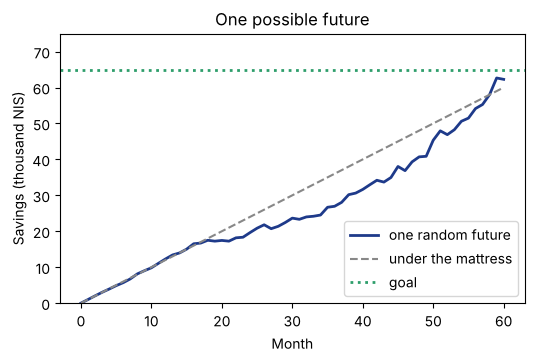

In [6]:
months = np.arange(num_months + 1)                 # 0, 1, 2, ..., 60
plt.figure(figsize=(6, 3.5))
plt.plot(months, np.array(one_future) / 1000, color="#1E3A8A", linewidth=2, label="one random future")
plt.plot(months, months * monthly_saving / 1000, "--", color="#888888", label="under the mattress")
plt.axhline(goal / 1000, color="#2E9E6B", linestyle=":", linewidth=2, label="goal")
plt.xlabel("Month")
plt.ylabel("Savings (thousand ILS)")
plt.ylim(0, 75)                                    # leave room above the goal line
plt.title("One possible future")
plt.legend()
plt.show()

**Try this:** run the two cells above again (without re-running the seed line). You get a **different** future each time!

## 4. One thousand futures
Same function, called 1,000 times in a loop. Then we turn the list of lists into a NumPy table (L09):
**one row per future, one column per month.**

In [7]:
num_futures = 1000
all_futures = []
for k in range(num_futures):
    all_futures.append(simulate_one_future(monthly_saving, average_return, risk))
all_futures = np.array(all_futures)      # 1000 rows (futures) x 61 columns (months)
print(all_futures.shape)

(1000, 61)


Let's draw 50 of them as thin see-through lines (`alpha=0.2`), plus the **median** future:
at every month, the middle value of all 1,000 futures (`axis=0` = go down the rows, one answer per column).

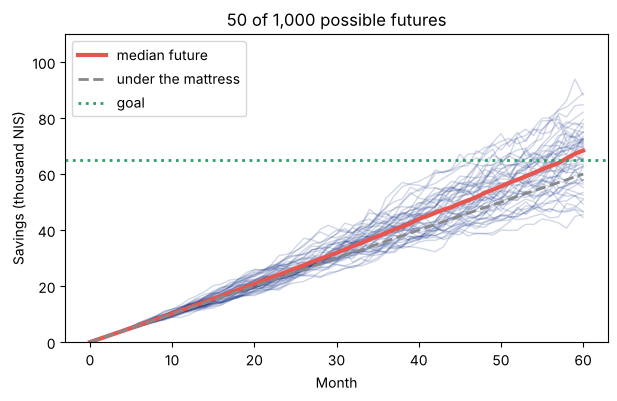

In [8]:
plt.figure(figsize=(7, 4))
for k in range(50):
    plt.plot(months, all_futures[k] / 1000, color="#1E3A8A", alpha=0.2, linewidth=1)
median_path = np.median(all_futures, axis=0)        # the middle value at each month
plt.plot(months, median_path / 1000, color="#E8554E", linewidth=3, label="median future")
plt.plot(months, months * monthly_saving / 1000, "--", color="#888888", linewidth=2, label="under the mattress")
plt.axhline(goal / 1000, color="#2E9E6B", linestyle=":", linewidth=2, label="goal")
plt.xlabel("Month")
plt.ylabel("Savings (thousand ILS)")
plt.ylim(0, 110)                                   # room for the legend at the top
plt.title("50 of 1,000 possible futures")
plt.legend(loc="upper left")
plt.show()

## 5. Where do we end up?
The last column (`[:, -1]`: every row, last column) is the amount after 60 months. A histogram (L10) shows how the endings are spread:

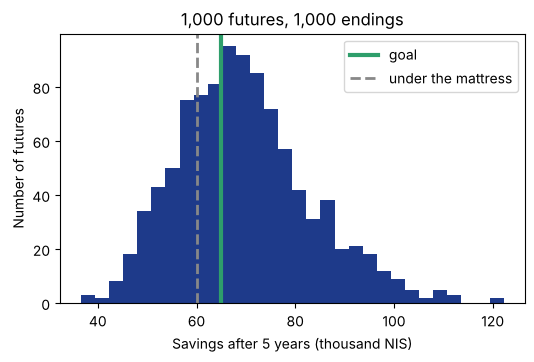

In [9]:
final_amounts = all_futures[:, -1]        # every row, last column = the end of month 60
plt.figure(figsize=(6, 3.5))
plt.hist(final_amounts / 1000, bins=30, color="#1E3A8A")
plt.axvline(goal / 1000, color="#2E9E6B", linewidth=3, label="goal")
plt.axvline(mattress / 1000, color="#888888", linestyle="--", linewidth=2, label="under the mattress")
plt.xlabel("Savings after 5 years (thousand ILS)")
plt.ylabel("Number of futures")
plt.title("1,000 futures, 1,000 endings")
plt.legend()
plt.show()

### The chance to reach the goal
`final_amounts >= goal` compares **all 1,000 endings at once** and gives True/False for each.
The mean of True/False values is the **fraction of True** (True counts as 1, False as 0).

In [10]:
reached = final_amounts >= goal          # True / False for every future
chance_goal = 100 * reached.mean()       # True counts as 1
print(f"Chance to reach {goal:,} ILS: {chance_goal:.0f}%")

Chance to reach 65,000 ILS: 61%


Same trick for the bad news: how often do we end with **less** than if we had kept the money under the mattress?

In [11]:
chance_loss = 100 * (final_amounts < mattress).mean()
print(f"Chance to end below the mattress: {chance_loss:.0f}%")

Chance to end below the mattress: 26%


Bad luck, typical luck, good luck: **percentiles** (L09). The 10th percentile = 10% of the futures ended below it.

In [12]:
summary = pd.DataFrame({
    "luck": ["bad (10th percentile)", "typical (median)", "good (90th percentile)"],
    "final amount (ILS)": [int(np.percentile(final_amounts, 10)),     # int(): drop the decimals
                           int(np.median(final_amounts)),
                           int(np.percentile(final_amounts, 90))],
})
print(summary)

                     luck  final amount (ILS)
0   bad (10th percentile)               53053
1        typical (median)               68399
2  good (90th percentile)               87624


**What did we learn?** The steady world said "you will make it". The random world says
"you make it in most futures, but in some you even end below the mattress". Same average, very different stories!

## 6. What if...?
Let's compare a few plans. For each plan we simulate 1,000 futures and count. A function makes it one line per plan:

In [13]:
def chance_to_reach_goal(monthly_saving, risk):
    finals = []
    for k in range(1000):
        future = simulate_one_future(monthly_saving, average_return, risk)
        finals.append(future[-1])                        # keep only the final amount
    return 100 * (np.array(finals) >= goal).mean()

plans = pd.DataFrame({
    "plan": ["1,000/month, risk 4%", "1,000/month, risk 8%", "1,100/month, risk 4%", "1,100/month, no risk"],
    "chance to reach goal (%)": [chance_to_reach_goal(1000, 0.04), chance_to_reach_goal(1000, 0.08),
                                 chance_to_reach_goal(1100, 0.04), chance_to_reach_goal(1100, 0.0)],
})
print(plans)

                   plan  chance to reach goal (%)
0  1,000/month, risk 4%                      63.9
1  1,000/month, risk 8%                      50.2
2  1,100/month, risk 4%                      80.5
3  1,100/month, no risk                     100.0


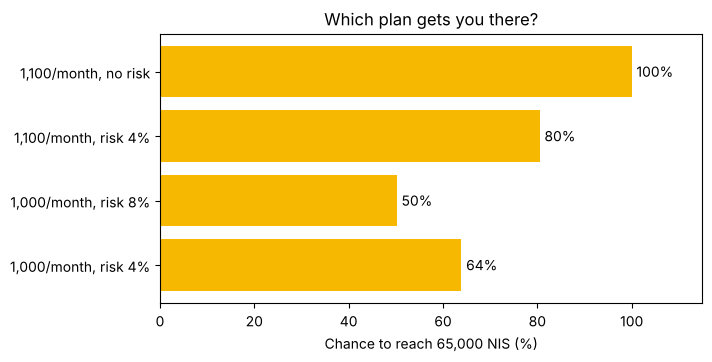

In [14]:
plt.figure(figsize=(7, 3.5))
plt.barh(plans["plan"], plans["chance to reach goal (%)"], color="#F6B800")   # barh = horizontal bars
for i in range(len(plans)):
    value = plans["chance to reach goal (%)"][i]
    plt.text(value + 1, i, f"{value:.0f}%", va="center")
plt.xlim(0, 115)
plt.xlabel("Chance to reach 65,000 ILS (%)")
plt.title("Which plan gets you there?")
plt.show()

**Wait, why does the first plan say about 64% here, but 61% in section 5?** It is the same plan, but a different set of
1,000 random futures. Monte Carlo answers **wobble a little** from run to run. More futures = less wobble.

Notice: more risk does **not** simply mean "more money". It spreads the futures out: more great endings **and** more bad ones.

> **Reminder:** toy model, made-up numbers, not financial advice. The point is the method: **when you can't predict
> one future, simulate many and count.** The same trick is used for weather forecasts, traffic, games and science.

## Challenges
**Easy**
- Change the goal to 70,000 ILS. How does the chance change?
- Change `num_months` to 10 years. Is the goal now easy?

**Medium**
- Add a "bonus month": every 12th month you save 3,000 ILS instead of 1,000 (hint: `if month % 12 == 11:` inside the loop).
- Plot the 10th and 90th percentile at every month (`np.percentile(all_futures, 10, axis=0)`) as two extra lines around the median.

**Spicy**
- Make a plot of "chance to reach the goal" against `risk` for risk = 0, 0.01, 0.02, ..., 0.10. Explain the shape in one sentence.